# Reading **DHI MIKE 21** flexible meshes with `pyramids-mesh`

**MIKE 21 FM** (Flexible Mesh) is DHI's shallow-water modelling engine; its mesh generator writes a plain-text **`.mesh`** file. The header line records the number of nodes, a node-id base, and a **projection string** (here `LONG/LAT`); then come the node coordinates and the element table. `pyramids-mesh` registers a `mike21` driver that parses it into a `UgridDataset`.

We read the bundled `minimal.mesh` (a unit square, two triangles) and exercise the toolkit.

## 3. Locate the data

`minimal.mesh` sits in `examples/data/`, two levels up from this notebook; we address it with a `Path`.

In [1]:
from pathlib import Path
DATA = Path("../../examples/data")
print((DATA / "minimal.mesh").resolve())

C:\python-environments\worktrees\pyramids-mesh\example-notebooks\examples\data\minimal.mesh


## 2. Imports

The import below is all the setup this adds: `UgridDataset` is the object every driver hands back (a `Mesh2d` or `Network1d` wrapper). Importing from `pyramids` also puts its vendored GDAL/PROJ data in place for you, so nothing about it is order-sensitive in a notebook -- just import the names you use.

In [2]:
from pyramids.netcdf.ugrid import UgridDataset
import numpy as np
import matplotlib.pyplot as plt

## 4. Read the file

The `LONG/LAT` token in the header is MIKE's projection field; this minimal fixture leaves the CRS unset, which is why `crs`/`epsg` read `None` below. A driver's only job is to parse the file and hand back a `UgridDataset`. We pass a `pathlib.Path` (never a `str`) and name the `driver` explicitly:

In [3]:
ds = UgridDataset.read_file(DATA / "minimal.mesh", driver="mike21")
ds

UgridDataset(mesh='mesh2d', n_node=4, n_face=2, n_edge=0, variables=['node_z'])

In [4]:
# reading switches matplotlib to Agg for headless safety; let cleopatra
# pick the notebook backend (inline) so the plots below embed
from cleopatra.config import Config
Config.set_matplotlib_backend()

'inline'

## 5. Explore the dataset

A `UgridDataset` exposes the mesh size, its coordinate reference system, and the data variables carried alongside the topology. `None` for `crs`/`epsg` simply means the source file declared no projection — the geometry is still valid, it is just unlocated in world space.

In [5]:
print('nodes :', ds.n_node)
print('faces :', ds.n_face)
print('crs   :', ds.crs)
print('epsg  :', ds.epsg)
print('vars  :', ds.data_variable_names)
print('bounds:', ds.bounds)

nodes : 4
faces : 2
crs   : None
epsg  : None
vars  : ['node_z']
bounds: (0.0, 0.0, 1.0, 1.0)


### Per-variable summary

`ds.summary()` returns a pandas `DataFrame` — one row per data variable with count, min, max, mean and standard deviation. A `std` of 0 means that variable is uniform across the mesh.

In [6]:
ds.summary()

,count,min,max,mean,std
variable,,,,,
node_z,4,0.0,0.0,0.0,0.0


### Global attributes

Each driver stamps provenance into `global_attributes` so you can trace a dataset back to the format it came from after it has been converted.

In [7]:
ds.global_attributes

{'source': 'DHI Mike21 mesh'}

## 6. The `Mesh2d` geometry

`ds.mesh` is a `Mesh2d`: node coordinates plus the face-node connectivity table. `face_node_connectivity.data` has shape `(n_face, k)` — row *i* lists the node indices of face *i* (padded for mixed element types). We also derive per-face areas and centroids from that topology.

In [8]:
m = ds.mesh
print('node_x shape           :', np.asarray(m.node_x).shape)
print('connectivity shape     :', np.asarray(m.face_node_connectivity.data).shape)
print('face_areas shape       :', np.asarray(m.face_areas).shape)
centroids = np.asarray(m.face_centroids)  # shape (2, n_face)
print('face_centroids shape   :', centroids.shape)
print('first face areas       :', np.asarray(m.face_areas)[:3])

node_x shape           : (4,)
connectivity shape     : (2, 3)
face_areas shape       : (2,)
face_centroids shape   : (2, 2)
first face areas       : [0.5 0.5]


## 7. Wireframe — the mesh skeleton

`plot_outline()` draws the bare mesh: every face edge, no data coloring. This is the fastest way to eyeball connectivity, element shapes and the overall extent.

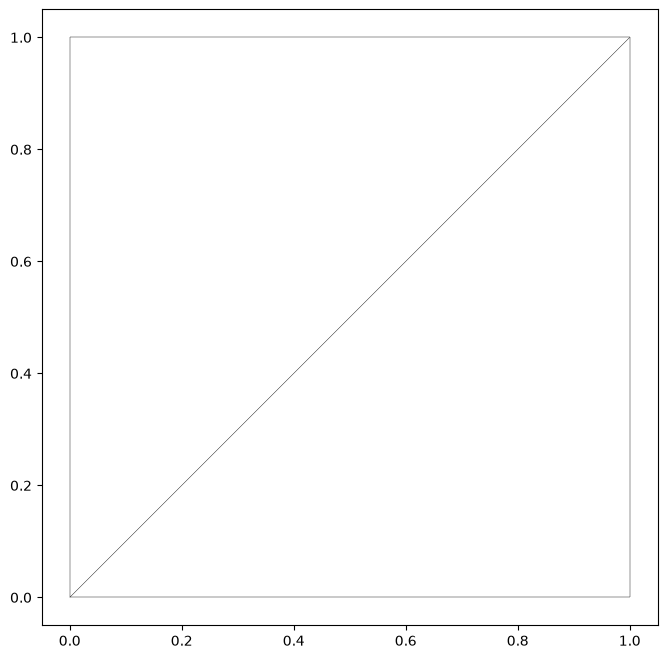

In [9]:
ds.plot_outline()


## 8. A data map

The `.mesh` format carries a node **z** value (bed level). On this flat fixture `node_z` is all zeros, so instead of a featureless map we **derive** a face variable — the cell area — with `with_variable(...)` and map that. This is the idiom for painting any computed quantity onto a mesh.

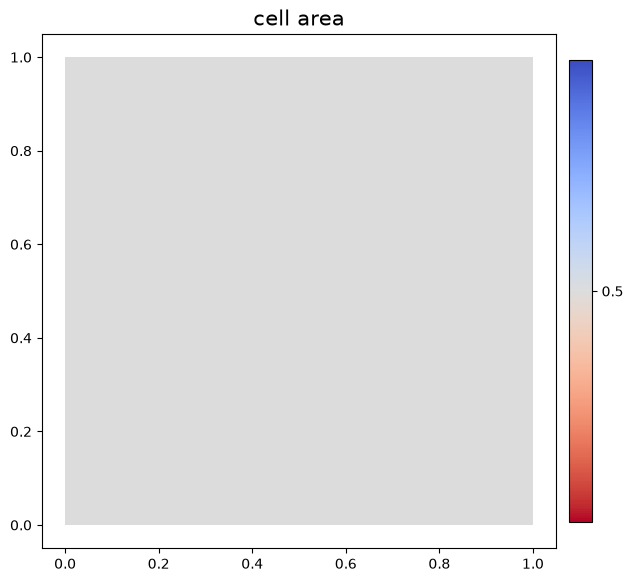

In [10]:
areas = np.asarray(ds.mesh.face_areas)
da = ds.with_variable("cell_area", areas, location="face")
da.plot("cell_area", cmap="viridis", colorbar=True, title="cell area")


Each of the two triangles has area 0.5, so the map is two equal patches — uniform by construction here, but on a real MIKE mesh this immediately reveals the fine/coarse resolution gradient.

## 9. GIS operations

Because a `UgridDataset` is a first-class `pyramids` object, the full geospatial toolkit works on it directly — no conversion step. Below are several operations, each visualised or interpreted. (Operations that need a source CRS, such as `to_crs`, are skipped here: this sample declares none.)

### 9a. Faces as polygons — `to_geodataframe()`

Every face becomes a shapely polygon in a GeoPandas `GeoDataFrame`, ready for a spatial join, an overlay, or export to any OGR vector format.

In [11]:
gdf = ds.to_geodataframe()
gdf.head()

,geometry
0,"POLYGON ((0 0, 1 0, 1 1, 0 0))"
1,"POLYGON ((0 0, 1 1, 0 1, 0 0))"


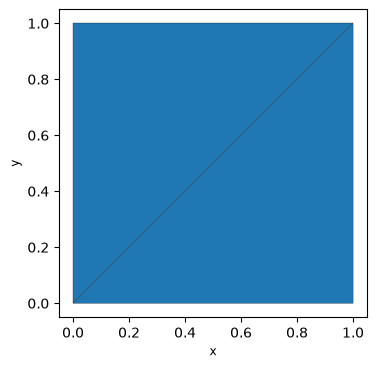

In [12]:
gdf.plot(edgecolor="k", linewidth=0.2, figsize=(5, 4))
plt.gca().set_aspect("equal")


The polygon mosaic is the mesh itself — each cell is now an independent vector feature. That is the bridge from a solver mesh to standard GIS.

### 9b. Outer boundary — `bounding_polygon()` and `exterior_edges()`

`bounding_polygon()` dissolves the faces into a single shapely polygon tracing the mesh outline, and `exterior_edges()` returns the indices of the mesh edges that lie on that boundary — their count is the boundary's edge length.

boundary edges: 4


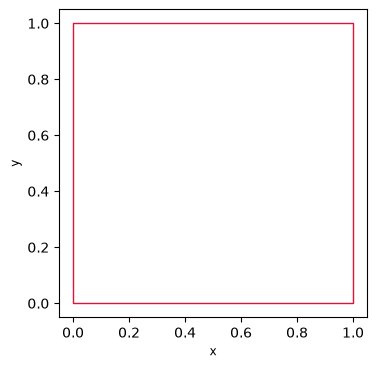

In [13]:
poly = ds.bounding_polygon()
n_boundary = len(ds.exterior_edges())
print('boundary edges:', n_boundary)
import geopandas as gpd
gpd.GeoSeries([poly]).plot(facecolor="none", edgecolor="crimson", figsize=(5, 4))
plt.gca().set_aspect("equal")


The crimson ring is the domain outline; `exterior_edges()` tells us how many element edges trace it — the rest of the edges are interior.

### 9c. Connectivity — `connected_components()`

`connected_components()` labels each face by the connected sub-mesh it belongs to. One unique label means the mesh is a single watertight piece; more than one would reveal detached islands. We attach the labels as a face variable and map them.

faces: 2  components: 1


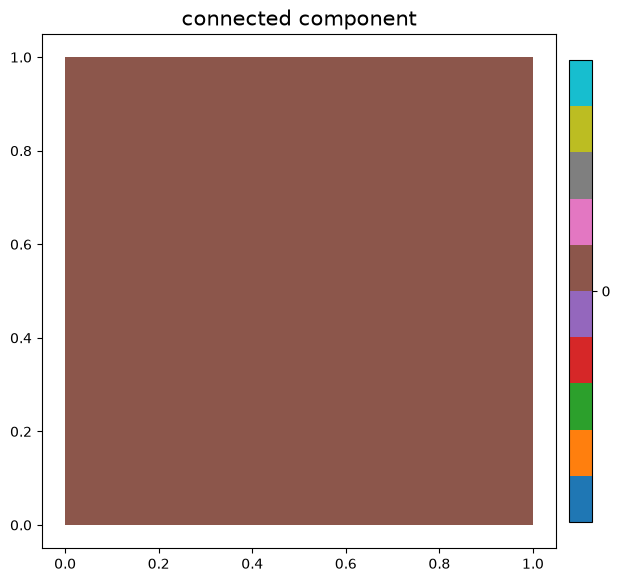

In [14]:
comp = np.asarray(ds.connected_components())
print('faces:', comp.size, ' components:', len(np.unique(comp)))
dc = ds.with_variable("component", comp.astype(float), location="face")
dc.plot("component", cmap="tab10", colorbar=True, title="connected component")


### 9d. Face adjacency — `sparse_adjacency()`

`sparse_adjacency()` returns the face-to-face adjacency as a SciPy sparse matrix (two faces are adjacent when they share an edge). Its sparsity pattern is the dual graph a solver walks; `nnz` counts the directed face-neighbour links.

shape: (2, 2)  nnz: 2


Text(0.5, 1.0, 'face adjacency')

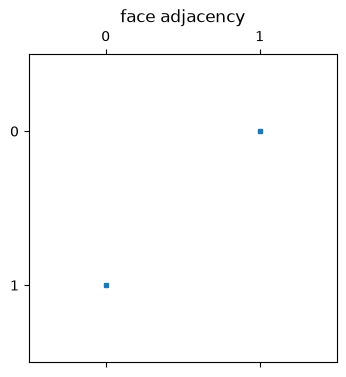

In [15]:
adj = ds.sparse_adjacency()
print('shape:', adj.shape, ' nnz:', adj.nnz)
plt.figure(figsize=(4, 4))
plt.spy(adj, markersize=3)
plt.title("face adjacency")


### 9e. Triangle circumcenters — `circumcenters()`

For a triangular mesh, `circumcenters()` returns the circumcircle centre of each face (shape `(2, n_face)`) — the sample points of the dual Voronoi mesh that finite-volume schemes use. We scatter them over the wireframe.

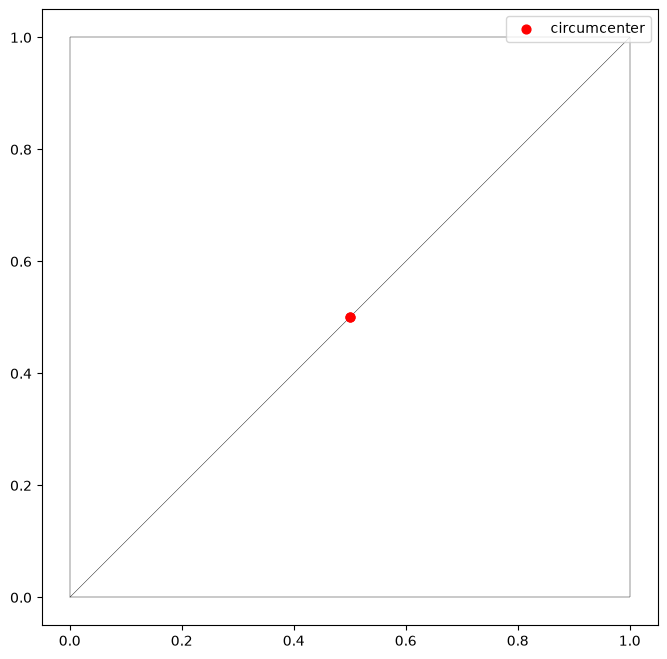

In [16]:
cc = np.asarray(ds.circumcenters())
ds.plot_outline()
plt.scatter(cc[0], cc[1], c="red", s=40, zorder=5, label="circumcenter")
plt.legend()


### 9f. Clip to a sub-region — `crop()`

`crop(bbox=...)` keeps the faces inside a bounding box; we clip to the lower-left quarter.

faces after crop: 0 of 2


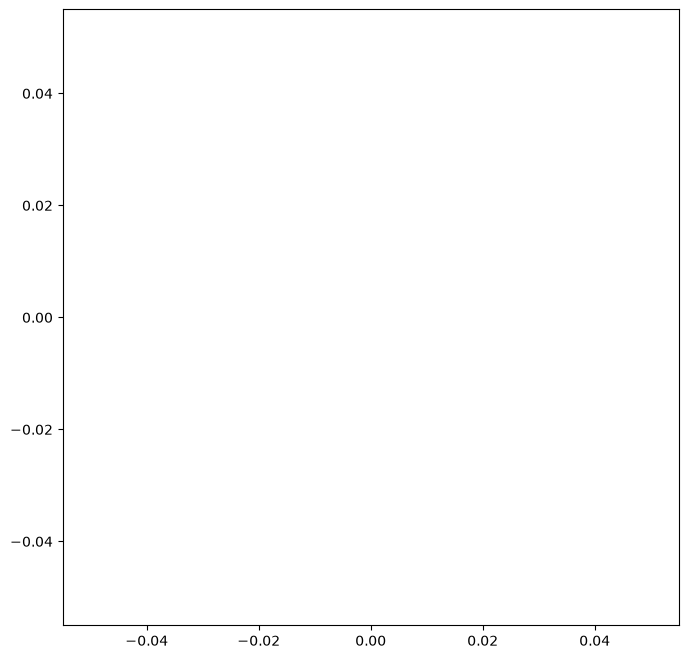

In [17]:
b = ds.bounds
sub = ds.crop(bbox=(b[0], b[1], (b[0]+b[2])/2, (b[1]+b[3])/2))
print('faces after crop:', sub.n_face, 'of', ds.n_face)
sub.plot_outline()


### 9g. Round-trip through UGRID NetCDF — `to_file()` / `to_xarray()`

`to_file(..., driver='ugrid')` writes the mesh to the CF/UGRID NetCDF convention — the lossless lingua franca every tool in the stack reads back. We write it, re-read it, and confirm the topology survived. `to_xarray()` hands the same content to the xarray ecosystem in memory.

In [18]:
import tempfile
out = Path(tempfile.mkdtemp()) / 'roundtrip.nc'
ds.to_file(out, driver="ugrid")
back = UgridDataset.read_file(out, driver="ugrid")
print('re-read nodes/faces:', back.n_node, back.n_face)
ds.to_xarray()

re-read nodes/faces: 4 2


<xarray.Dataset> Size: 148B
Dimensions:            (mesh2d_scalar: 1, mesh2d_nNodes: 4, mesh2d_nFaces: 2,
                        mesh2d_nMaxFaceNodes: 3)
Dimensions without coordinates: mesh2d_scalar, mesh2d_nNodes, mesh2d_nFaces,
                                mesh2d_nMaxFaceNodes
Data variables:
    mesh2d             (mesh2d_scalar) int32 4B 0
    mesh2d_node_x      (mesh2d_nNodes) float64 32B 0.0 1.0 1.0 0.0
    mesh2d_node_y      (mesh2d_nNodes) float64 32B 0.0 0.0 1.0 1.0
    mesh2d_face_nodes  (mesh2d_nFaces, mesh2d_nMaxFaceNodes) int64 48B 1 2 ... 4
    node_z             (mesh2d_nNodes) float64 32B 0.0 0.0 0.0 0.0
Attributes:
    Conventions:  CF-1.8 UGRID-1.0

## 10. Takeaway

The `mike21` driver reads a DHI `.mesh` into a `UgridDataset`. Node bathymetry comes through as a variable, any computed field can be attached with `with_variable`, and the mesh then flows into the same vector/clip/round-trip toolkit as every other format.